# Can a phone-recorded "ahh" reveal Parkinson's?

This notebook regenerates every number and figure in the README and the paper.
It downloads the dataset from figshare (CC BY 4.0), extracts acoustic features,
and evaluates each model under **repeated stratified 5-fold cross-validation
(10 repeats, 50 folds, seed 42)**.

It also re-runs the original pipeline *as it was first reported*, so the effect of
each correction can be measured instead of asserted:

1. **Feature selection leak.** The original SVM used five MFCC statistics chosen by
   their correlation with the label on all 81 recordings, test folds included.
   Here the five features are chosen inside each training fold.
2. **Threshold leak.** The original 0.45 threshold was tuned on the same LOOCV
   predictions it was then scored on. Here it is tuned by an inner CV on the
   training fold.
3. **Early-stopping leak.** The original CNN early-stopped (and restored its best
   weights) on the test fold. Here it early-stops on a validation split carved out
   of the training fold.
4. **Age confound.** The healthy controls are on average 19 years younger than the
   people with Parkinson's. A model that sees only age and sex is the baseline the
   voice models have to beat.

In [1]:
import sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'praat-parselmouth==0.4.7'], check=True)

In [2]:
import hashlib
import json
import random
import urllib.request
import warnings
import zipfile
from pathlib import Path

import librosa
import numpy as np
import pandas as pd
import parselmouth
import torch
from parselmouth.praat import call
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score
from sklearn.model_selection import (LeaveOneOut, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

ROOT = Path.cwd()
DATA_DIR = ROOT / 'data'
RAW_DIR = DATA_DIR / 'raw'
ASSETS_DIR = ROOT / 'assets'
RESULTS_DIR = ROOT / 'results'
for d in (RAW_DIR, ASSETS_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

## 1. Data

*Voice Samples for Patients with Parkinson's Disease and Healthy Controls*
(Prior, Virmani, Iyer, Larson-Prior, Kemp, Rahmatallah et al., figshare 2023,
[doi:10.6084/m9.figshare.23849127](https://doi.org/10.6084/m9.figshare.23849127), CC BY 4.0).
81 sustained /a/ vowels recorded over the phone at 8 kHz: 41 healthy controls (HC) and
40 people with Parkinson's disease (PD), plus each participant's age and sex.

In [3]:
FIGSHARE_FILES = {
    'HC_AH.zip': ('41836713', '55fd33d365380372dcfbae4f7f520246'),
    'PD_AH.zip': ('41836710', '2e525e419abdad509e5cbf201e30ef36'),
    'Demographics_age_sex.xlsx': ('41836707', '15bfde0fcb441c55dcd2fc3138c3a672'),
}


def md5sum(path):
    return hashlib.md5(path.read_bytes()).hexdigest()


def fetch_dataset():
    for name, (file_id, md5) in FIGSHARE_FILES.items():
        path = RAW_DIR / name
        if not path.exists() or md5sum(path) != md5:
            print(f'Downloading {name} from figshare...')
            urllib.request.urlretrieve(f'https://ndownloader.figshare.com/files/{file_id}', path)
        if md5sum(path) != md5:
            raise RuntimeError(f'{name}: checksum mismatch, the figshare file changed')
        if name.endswith('.zip') and not (RAW_DIR / name[:-4]).exists():
            with zipfile.ZipFile(path) as zf:
                zf.extractall(RAW_DIR)


fetch_dataset()

hc_files = sorted((RAW_DIR / 'HC_AH').glob('*.wav'))
pd_files = sorted((RAW_DIR / 'PD_AH').glob('*.wav'))
file_paths = [str(f) for f in hc_files + pd_files]
labels = np.array([0] * len(hc_files) + [1] * len(pd_files))

demo = pd.read_excel(RAW_DIR / 'Demographics_age_sex.xlsx').set_index('Sample ID')
sample_ids = [Path(p).stem for p in file_paths]
age = demo.loc[sample_ids, 'Age'].to_numpy(float)
sex_male = (demo.loc[sample_ids, 'Sex'] == 'M').to_numpy(float)
assert (demo.loc[sample_ids, 'Label'].map({'HC': 0, 'PwPD': 1}).to_numpy() == labels).all()

print(f'HC: {len(hc_files)}, PD: {len(pd_files)}, total: {len(file_paths)}')

HC: 41, PD: 40, total: 81


### Who is in the dataset

The two groups are not age-matched. This matters more than anything else in this notebook:
voices change with age, so any voice feature that tracks age will also "detect" Parkinson's here.

In [4]:
demo_table = pd.DataFrame({
    'n': [int((labels == g).sum()) for g in (0, 1)],
    'age_mean': [age[labels == g].mean() for g in (0, 1)],
    'age_sd': [age[labels == g].std(ddof=1) for g in (0, 1)],
    'age_min': [age[labels == g].min() for g in (0, 1)],
    'age_max': [age[labels == g].max() for g in (0, 1)],
    'aged_60_plus': [int(((labels == g) & (age >= 60)).sum()) for g in (0, 1)],
    'female': [int(((labels == g) & (sex_male == 0)).sum()) for g in (0, 1)],
    'male': [int(((labels == g) & (sex_male == 1)).sum()) for g in (0, 1)],
}, index=['HC', 'PD']).round(1)
age_test = stats.mannwhitneyu(age[labels == 0], age[labels == 1])
print(demo_table.to_string())
print(f'\nAge difference, Mann-Whitney U: p = {age_test.pvalue:.1e}')
print(f'AUC of age alone (no model, no CV): {roc_auc_score(labels, age):.3f}')

     n  age_mean  age_sd  age_min  age_max  aged_60_plus  female  male
HC  41      47.7    14.3     18.0     79.0             7      25    16
PD  40      67.0     9.0     43.1     85.3            31      19    21

Age difference, Mann-Whitney U: p = 1.7e-08
AUC of age alone (no model, no CV): 0.864


## 2. Acoustic features

The same 91 features as the original work: F0 statistics, formants F1-F4, RMS energy,
jitter, shimmer, HNR, 13 MFCCs (mean, std, delta, delta-delta) and four spectral descriptors.

In [5]:
FEATURE_SR = 16000


def extract_f0(sound):
    pitch = call(sound, 'To Pitch', 0.0, 75, 600)
    f0 = pitch.selected_array['frequency']
    f0 = f0[f0 != 0]
    if len(f0) == 0:
        return {k: 0 for k in ['f0_mean', 'f0_std', 'f0_min', 'f0_max', 'f0_range',
                               'f0_cv', 'f0_median', 'f0_iqr', 'f0_skew', 'f0_kurtosis']}
    return {
        'f0_mean': np.mean(f0), 'f0_std': np.std(f0), 'f0_min': np.min(f0),
        'f0_max': np.max(f0), 'f0_range': np.ptp(f0),
        'f0_cv': np.std(f0) / np.mean(f0), 'f0_median': np.median(f0),
        'f0_iqr': np.percentile(f0, 75) - np.percentile(f0, 25),
        'f0_skew': stats.skew(f0), 'f0_kurtosis': stats.kurtosis(f0),
    }


def extract_formants(sound):
    features = {}
    formants = call(sound, 'To Formant (burg)', 0.0, 5, 5500, 0.025, 50)
    for i in range(1, 5):
        values = [call(formants, 'Get value at time', i, t, 'Hertz', 'Linear')
                  for t in np.linspace(0, sound.duration, 50)]
        values = [v for v in values if not np.isnan(v) and v > 0]
        features[f'formant_{i}_mean'] = np.mean(values) if values else 0
        features[f'formant_{i}_std'] = np.std(values) if values else 0
    return features


def extract_energy(y):
    rms = librosa.feature.rms(y=y)[0]
    return {
        'rms_mean': np.mean(rms), 'rms_std': np.std(rms), 'rms_range': np.ptp(rms),
        'rms_max': np.max(rms), 'rms_min': np.min(rms),
        'energy_mean': np.mean(y ** 2), 'energy_std': np.std(y ** 2),
    }


def extract_jitter_shimmer_hnr(sound):
    pp = call(sound, 'To PointProcess (periodic, cc)', 75, 600)
    feats = {
        'jitter_local': call(pp, 'Get jitter (local)', 0, 0, 0.0001, 0.02, 1.3),
        'jitter_abs': call(pp, 'Get jitter (local, absolute)', 0, 0, 0.0001, 0.02, 1.3),
        'jitter_rap': call(pp, 'Get jitter (rap)', 0, 0, 0.0001, 0.02, 1.3),
        'jitter_ppq5': call(pp, 'Get jitter (ppq5)', 0, 0, 0.0001, 0.02, 1.3),
        'shimmer_local': call([sound, pp], 'Get shimmer (local)', 0, 0, 0.0001, 0.02, 1.3, 1.6),
        'shimmer_db': call([sound, pp], 'Get shimmer (local_dB)', 0, 0, 0.0001, 0.02, 1.3, 1.6),
        'shimmer_apq3': call([sound, pp], 'Get shimmer (apq3)', 0, 0, 0.0001, 0.02, 1.3, 1.6),
        'shimmer_apq5': call([sound, pp], 'Get shimmer (apq5)', 0, 0, 0.0001, 0.02, 1.3, 1.6),
    }
    harm = call(sound, 'To Harmonicity (cc)', 0.01, 75, 0.1, 1.0)
    hnr = call(harm, 'Get mean', 0, 0)
    hnr = 0 if hnr == -200 or np.isnan(hnr) else hnr
    feats.update({'hnr': hnr, 'nhr': 1 / (10 ** (hnr / 10)) if hnr > 0 else 1})
    return feats


def extract_mfcc(y, sr, n_mfcc=13):
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
    delta = librosa.feature.delta(mfccs)
    delta2 = librosa.feature.delta(mfccs, order=2)
    features = {}
    for i in range(n_mfcc):
        features[f'mfcc_mean_{i + 1}'] = np.mean(mfccs[i])
        features[f'mfcc_std_{i + 1}'] = np.std(mfccs[i])
        features[f'mfcc_delta_{i + 1}'] = np.mean(delta[i])
        features[f'mfcc_delta2_{i + 1}'] = np.mean(delta2[i])
    return features


def extract_spectral(y, sr):
    return {
        'spectral_centroid': np.mean(librosa.feature.spectral_centroid(y=y, sr=sr)),
        'spectral_bandwidth': np.mean(librosa.feature.spectral_bandwidth(y=y, sr=sr)),
        'spectral_rolloff': np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr)),
        'zcr': np.mean(librosa.feature.zero_crossing_rate(y)),
    }


def extract_features(path):
    y, sr = librosa.load(path, sr=FEATURE_SR)
    sound = parselmouth.Sound(path)
    features = {}
    features.update(extract_f0(sound))
    features.update(extract_formants(sound))
    features.update(extract_energy(y))
    features.update(extract_jitter_shimmer_hnr(sound))
    features.update(extract_mfcc(y, sr))
    features.update(extract_spectral(y, sr))
    return features


features_path = DATA_DIR / 'features.csv'
if not features_path.exists():
    pd.DataFrame([extract_features(p) for p in tqdm(file_paths, desc='Features')],
                 index=pd.Index(sample_ids, name='sample_id')).astype('float64').to_csv(features_path)
# round_trip parsing gives back the exact floats that were written, so a fresh run and a cached run agree
feat_df = pd.read_csv(features_path, index_col='sample_id', float_precision='round_trip').loc[sample_ids]

feature_cols = list(feat_df.columns)
X_all = feat_df.to_numpy(float)
y = labels
print(f'{X_all.shape[1]} features x {X_all.shape[0]} recordings')

91 features x 81 recordings


## 3. Evaluation protocol

Every model below sees exactly the same 50 train/test splits.

In [6]:
METRICS = ['accuracy', 'auc', 'sensitivity', 'specificity', 'f1']
OUTER = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
SPLITS = list(OUTER.split(X_all, y))
THRESHOLDS = np.round(np.arange(0.30, 0.701, 0.05), 2)


def fold_metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        'accuracy': accuracy_score(y_true, pred),
        'auc': roc_auc_score(y_true, prob),
        'sensitivity': recall_score(y_true, pred, pos_label=1, zero_division=0),
        'specificity': recall_score(y_true, pred, pos_label=0, zero_division=0),
        'f1': f1_score(y_true, pred, zero_division=0),
    }


def summarize(fold_rows):
    df = pd.DataFrame(fold_rows)[METRICS]
    return {m: {'mean': float(df[m].mean()), 'sd': float(df[m].std(ddof=1))} for m in METRICS} | {
        'n_folds': len(df)}


def youden_threshold(y_true, prob):
    scores = [recall_score(y_true, prob >= t, pos_label=1, zero_division=0)
              + recall_score(y_true, prob >= t, pos_label=0, zero_division=0) - 1 for t in THRESHOLDS]
    return float(THRESHOLDS[int(np.argmax(scores))])


class TopKByCorrelation(BaseEstimator, TransformerMixin):
    """Keep the k columns most correlated (|Pearson r| with the 0/1 label) in the data it is fit on.
    Columns listed in `always_keep` bypass the ranking (used for age and sex)."""

    def __init__(self, k=5, always_keep=()):
        self.k = k
        self.always_keep = always_keep

    def fit(self, X, y):
        X = np.asarray(X, float)
        ranked = [i for i in range(X.shape[1]) if i not in self.always_keep]
        Xc = X[:, ranked] - X[:, ranked].mean(0)
        yc = np.asarray(y, float) - np.mean(y)
        r = (Xc * yc[:, None]).sum(0) / (np.sqrt((Xc ** 2).sum(0) * (yc ** 2).sum()) + 1e-12)
        top = [ranked[i] for i in np.argsort(-np.abs(r))[:self.k]]
        self.columns_ = top + list(self.always_keep)
        return self

    def transform(self, X):
        return np.asarray(X, float)[:, self.columns_]


def svm():
    return SVC(kernel='rbf', C=10, gamma=0.1, probability=True, random_state=SEED)


def evaluate(make_model, X, splits=SPLITS, tune_threshold=False, desc=None):
    """Fit on each training fold, score on its test fold. With tune_threshold, the decision
    threshold is chosen by Youden's J on inner 5-fold CV predictions of the training fold."""
    rows, rows_tuned, chosen = [], [], []
    for train_idx, test_idx in tqdm(splits, desc=desc, leave=False):
        model = make_model().fit(X[train_idx], y[train_idx])
        prob = model.predict_proba(X[test_idx])[:, 1]
        rows.append(fold_metrics(y[test_idx], prob))
        if tune_threshold:
            inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
            inner_prob = cross_val_predict(make_model(), X[train_idx], y[train_idx], cv=inner,
                                           method='predict_proba')[:, 1]
            t = youden_threshold(y[train_idx], inner_prob)
            chosen.append(t)
            rows_tuned.append(fold_metrics(y[test_idx], prob, t))
    out = {'t=0.5': summarize(rows)}
    if tune_threshold:
        out['t=inner'] = summarize(rows_tuned)
        out['t=inner']['thresholds_chosen'] = pd.Series(chosen).value_counts().sort_index().to_dict()
    out['_folds'] = rows
    return out


def show(name, res, key='t=0.5'):
    s = res[key]
    print(f"{name:<44}" + ''.join(f"{s[m]['mean']:>8.3f}±{s[m]['sd']:.2f}" for m in METRICS))


HEADER = f"{'':<44}" + ''.join(f'{m[:11]:>13}' for m in METRICS)

## 4. The SVM as originally reported

The five MFCC statistics below are the ones the original work selected by correlation with the
label over all 81 recordings. Re-running its exact protocol reproduces its numbers.

In [7]:
ORIGINAL_TOP5 = ['mfcc_std_1', 'mfcc_mean_2', 'mfcc_std_2', 'mfcc_std_12', 'mfcc_std_11']
X_top5 = feat_df[ORIGINAL_TOP5].to_numpy(float)


def original_svm():
    return Pipeline([('scaler', StandardScaler()), ('clf', svm())])


orig_5fold = evaluate(original_svm, X_top5,
                      splits=list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_top5, y)))

loo_prob = np.zeros(len(y))
for train_idx, test_idx in LeaveOneOut().split(X_top5):
    loo_prob[test_idx] = original_svm().fit(X_top5[train_idx], y[train_idx]).predict_proba(X_top5[test_idx])[:, 1]
loo_t = youden_threshold(y, loo_prob)
orig_loo = fold_metrics(y, loo_prob)
orig_loo_tuned = fold_metrics(y, loo_prob, loo_t)

print(HEADER)
show('Original: 5-fold, seed 42, t=0.5', orig_5fold)
print(f"{'Original: LOOCV, t=0.5':<44}" + ''.join(f'{orig_loo[m]:>13.3f}' for m in METRICS))
print(f"{f'Original: LOOCV, t={loo_t} tuned on itself':<44}" + ''.join(f'{orig_loo_tuned[m]:>13.3f}' for m in METRICS))

                                                 accuracy          auc  sensitivity  specificity           f1
Original: 5-fold, seed 42, t=0.5               0.827±0.07   0.863±0.06   0.850±0.14   0.806±0.06   0.825±0.08
Original: LOOCV, t=0.5                              0.741        0.806        0.750        0.732        0.741
Original: LOOCV, t=0.45 tuned on itself             0.741        0.806        0.800        0.683        0.753


## 5. Removing the leaks from the SVM

In [8]:
svm_leaky = evaluate(original_svm, X_top5, desc='SVM, leaky')


def clean_svm():
    return Pipeline([('select', TopKByCorrelation(k=5)), ('scaler', StandardScaler()), ('clf', svm())])


svm_clean = evaluate(clean_svm, X_all, tune_threshold=True, desc='SVM, clean')

print(HEADER)
show('SVM, original top-5 (leaky), 10x5 CV', svm_leaky)
show('SVM, top-5 chosen in-fold, t=0.5', svm_clean)
show('SVM, top-5 chosen in-fold, t tuned in-fold', svm_clean, 't=inner')
print('\nThresholds chosen in-fold:', svm_clean['t=inner']['thresholds_chosen'])

                                                 accuracy          auc  sensitivity  specificity           f1
SVM, original top-5 (leaky), 10x5 CV           0.771±0.08   0.837±0.07   0.785±0.15   0.756±0.12   0.766±0.10
SVM, top-5 chosen in-fold, t=0.5               0.716±0.11   0.781±0.11   0.680±0.17   0.751±0.16   0.697±0.12
SVM, top-5 chosen in-fold, t tuned in-fold     0.699±0.10   0.781±0.11   0.682±0.19   0.716±0.20   0.683±0.12

Thresholds chosen in-fold: {0.3: 1, 0.35: 3, 0.4: 10, 0.45: 7, 0.5: 11, 0.55: 11, 0.6: 5, 0.65: 1, 0.7: 1}


In [9]:
selection_counts = pd.Series(
    [feature_cols[c] for tr, _ in SPLITS for c in TopKByCorrelation(5).fit(X_all[tr], y[tr]).columns_]
).value_counts()
print('How often each feature made the in-fold top 5 (out of 50 folds):')
print(selection_counts.head(12).to_string())

How often each feature made the in-fold top 5 (out of 50 folds):
rms_range      50
mfcc_std_1     39
mfcc_mean_2    31
mfcc_std_2     28
rms_max        23
rms_std        16
mfcc_std_4     12
mfcc_std_11    10
mfcc_std_12     9
mfcc_std_7      7
mfcc_std_9      7
mfcc_std_3      6


## 6. The age confound

If age and sex alone predict the label as well as the voice does, the voice models may be hearing
age. Two checks: does adding voice features to age and sex improve on age and sex alone, and does
the voice model still work in a subgroup where the two groups have similar ages?

In [10]:
X_demo = np.column_stack([age, sex_male])
X_voice_demo = np.column_stack([X_all, age, sex_male])
n_voice = X_all.shape[1]


def demo_logreg():
    return Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression())])


def demo_svm():
    return Pipeline([('scaler', StandardScaler()), ('clf', svm())])


def voice_demo_svm():
    return Pipeline([('select', TopKByCorrelation(k=5, always_keep=(n_voice, n_voice + 1))),
                     ('scaler', StandardScaler()), ('clf', svm())])


age_lr = evaluate(demo_logreg, X_demo, desc='Age+sex LR')
age_svm = evaluate(demo_svm, X_demo, desc='Age+sex SVM')
voice_age_svm = evaluate(voice_demo_svm, X_voice_demo, desc='Voice+age+sex SVM')

print(HEADER)
show('Age + sex only, logistic regression', age_lr)
show('Age + sex only, SVM', age_svm)
show('Voice top-5 + age + sex, SVM', voice_age_svm)
show('Voice top-5 only, SVM (from section 5)', svm_clean)

auc_gain = np.array([a['auc'] - b['auc'] for a, b in zip(voice_age_svm['_folds'], age_svm['_folds'])])
print(f'\nAUC gain from adding voice to age + sex (same SVM, same folds): '
      f'{auc_gain.mean():+.3f} (sd {auc_gain.std(ddof=1):.3f}), positive in {(auc_gain > 0).sum()}/50 folds')

                                                 accuracy          auc  sensitivity  specificity           f1
Age + sex only, logistic regression            0.818±0.10   0.856±0.09   0.807±0.16   0.828±0.11   0.808±0.12
Age + sex only, SVM                            0.820±0.10   0.860±0.09   0.855±0.13   0.786±0.13   0.822±0.10
Voice top-5 + age + sex, SVM                   0.786±0.10   0.861±0.09   0.790±0.15   0.782±0.14   0.781±0.12
Voice top-5 only, SVM (from section 5)         0.716±0.11   0.781±0.11   0.680±0.17   0.751±0.16   0.697±0.12

AUC gain from adding voice to age + sex (same SVM, same folds): +0.001 (sd 0.089), positive in 24/50 folds


### Age-overlap subgroup

Ages 55-79 is where the two groups overlap with similar means. This range was fixed by looking at
the ages only, before any model was scored on it. It leaves just 11 healthy controls, so with
2-3 controls per test fold, per-fold sensitivity and specificity are not meaningful; the AUC is
computed on the pooled out-of-fold predictions of each repeat (10 values).

In [11]:
AGE_LO, AGE_HI = 55, 79
sub = np.where((age >= AGE_LO) & (age <= AGE_HI))[0]
print(f'Subgroup {AGE_LO}-{AGE_HI}: HC n={(y[sub] == 0).sum()} (mean age {age[sub][y[sub] == 0].mean():.1f}), '
      f'PD n={(y[sub] == 1).sum()} (mean age {age[sub][y[sub] == 1].mean():.1f})')


def pooled_auc_by_repeat(make_model, X, idx, n_repeats=10):
    aucs = []
    for r in range(n_repeats):
        cv = StratifiedKFold(5, shuffle=True, random_state=SEED + r)
        prob = cross_val_predict(make_model(), X[idx], y[idx], cv=cv, method='predict_proba')[:, 1]
        aucs.append(roc_auc_score(y[idx], prob))
    return {'mean': float(np.mean(aucs)), 'sd': float(np.std(aucs, ddof=1)), 'values': aucs}


subgroup = {
    'age_sex_logreg': pooled_auc_by_repeat(demo_logreg, X_demo, sub),
    'voice_svm': pooled_auc_by_repeat(clean_svm, X_all, sub),
}
for k, v in subgroup.items():
    print(f'{k:<20} pooled AUC {v["mean"]:.3f} ± {v["sd"]:.3f}')

Subgroup 55-79: HC n=11 (mean age 65.7), PD n=34 (mean age 67.5)
age_sex_logreg       pooled AUC 0.324 ± 0.096
voice_svm            pooled AUC 0.659 ± 0.090


In [12]:
N_PERMUTATIONS = 1000
rng_perm = np.random.default_rng(SEED)
y_backup = y.copy()
perm_aucs = []
for _ in tqdm(range(N_PERMUTATIONS), desc='Permutations', leave=False):
    y = y_backup.copy()
    y[sub] = rng_perm.permutation(y_backup[sub])
    perm_aucs.append(pooled_auc_by_repeat(clean_svm, X_all, sub)['mean'])
y = y_backup
perm_aucs = np.array(perm_aucs)
subgroup['voice_svm']['permutation_p'] = float(
    (1 + (perm_aucs >= subgroup['voice_svm']['mean']).sum()) / (1 + N_PERMUTATIONS))
subgroup['voice_svm']['permutation_null_mean'] = float(perm_aucs.mean())
print(f"Voice SVM in subgroup: AUC {subgroup['voice_svm']['mean']:.3f}, "
      f"permutation null mean {perm_aucs.mean():.3f}, p = {subgroup['voice_svm']['permutation_p']:.3f} "
      f"({N_PERMUTATIONS} label permutations within the subgroup)")

Voice SVM in subgroup: AUC 0.659, permutation null mean 0.486, p = 0.037 (1000 label permutations within the subgroup)


## 7. The CNN, with and without the early-stopping leak

ParkCNN (residual blocks with squeeze-and-excitation, 330K parameters) on 32-band mel
spectrograms at the native 8 kHz, with deltas, mixup and four-way augmentation, as in the
original work. Two training regimes on the same folds:

* **Leaky (original):** the test fold doubles as the validation set for early stopping and the
  learning-rate schedule, and the best weights on it are restored.
* **Clean:** 20% of the training fold is held out for early stopping; the test fold is only scored.

To keep the run under a few minutes on a laptop CPU, the three waveform augmentations (noise,
time stretch, pitch shift) are precomputed: five random variants per recording and type, drawn
once with the global seed. Each epoch picks one variant per type, and SpecAugment masks are drawn
fresh. A recording's variants are only ever used when that recording is in the training fold.

In [13]:
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split

CNN_SR, N_MELS, FMAX, MAX_LEN = 8000, 32, 4000, 64
N_VARIANTS, EPOCHS, PATIENCE, BATCH = 5, 50, 10, 16
CNN_REPEATS = 10  # repeats of the 5-fold split (10 -> all 50 folds)
device = 'cpu'
torch.set_num_threads(max(1, torch.get_num_threads()))


def to_mel(wave):
    mel = librosa.power_to_db(
        librosa.feature.melspectrogram(y=wave, sr=CNN_SR, n_mels=N_MELS, fmax=FMAX), ref=np.max)
    if mel.shape[1] < MAX_LEN:
        mel = np.pad(mel, ((0, 0), (0, MAX_LEN - mel.shape[1])), mode='reflect')
    return mel[:, :MAX_LEN].astype(np.float32)


def build_spectrogram_bank():
    rng = np.random.default_rng(SEED)
    clean, variants = [], []
    for path in tqdm(file_paths, desc='Spectrograms', leave=False):
        wave, _ = librosa.load(path, sr=CNN_SR)
        clean.append(to_mel(wave))
        per_type = []
        for aug in ('noise', 'stretch', 'pitch'):
            mels = []
            for _ in range(N_VARIANTS):
                if aug == 'noise':
                    w = wave + 0.005 * rng.standard_normal(len(wave))
                elif aug == 'stretch':
                    w = librosa.effects.time_stretch(wave, rate=rng.uniform(0.92, 1.08))
                else:
                    w = librosa.effects.pitch_shift(wave, sr=CNN_SR, n_steps=rng.uniform(-0.5, 0.5))
                mels.append(to_mel(w.astype(np.float32)))
            per_type.append(np.stack(mels))
        variants.append(np.stack(per_type))
    return np.stack(clean), np.stack(variants)  # (81, 32, 64), (81, 3, 5, 32, 64)


bank_path = DATA_DIR / 'spectrogram_bank.npz'
if bank_path.exists():
    with np.load(bank_path) as z:
        MEL_CLEAN, MEL_VARIANTS = z['clean'], z['variants']
else:
    MEL_CLEAN, MEL_VARIANTS = build_spectrogram_bank()
    np.savez_compressed(bank_path, clean=MEL_CLEAN, variants=MEL_VARIANTS)
print('Spectrogram bank:', MEL_CLEAN.shape, MEL_VARIANTS.shape)


def spec_augment(spec, rng, freq_mask=10, time_mask=20):
    spec = spec.copy()
    nf, nt = spec.shape
    f, f0 = rng.integers(0, freq_mask), rng.integers(0, max(1, nf - freq_mask))
    t, t0 = rng.integers(0, time_mask), rng.integers(0, max(1, nt - time_mask))
    spec[f0:f0 + f, :] = spec.min()
    spec[:, t0:t0 + t] = spec.min()
    return spec


def epoch_batch(idx, rng):
    """One epoch of training data: each recording once clean and once per augmentation type."""
    xs, ys = [], []
    for i in idx:
        xs.append(MEL_CLEAN[i])
        ys.append(y[i])
        for a in range(3):
            xs.append(spec_augment(MEL_VARIANTS[i, a, rng.integers(N_VARIANTS)], rng))
            ys.append(y[i])
    return torch.from_numpy(np.stack(xs)).unsqueeze(1), torch.tensor(ys, dtype=torch.float32).unsqueeze(1)


def compute_deltas(spec):
    spec = spec.squeeze(1)
    delta = torch.zeros_like(spec)
    delta[:, :, 1:-1] = (spec[:, :, 2:] - spec[:, :, :-2]) / 2
    delta[:, :, 0] = spec[:, :, 1] - spec[:, :, 0]
    delta[:, :, -1] = spec[:, :, -1] - spec[:, :, -2]
    delta2 = torch.zeros_like(spec)
    delta2[:, :, 1:-1] = (delta[:, :, 2:] - delta[:, :, :-2]) / 2
    delta2[:, :, 0] = delta[:, :, 1] - delta[:, :, 0]
    delta2[:, :, -1] = delta[:, :, -1] - delta[:, :, -2]
    return torch.stack([spec, delta, delta2], dim=1)


class SEBlock(nn.Module):
    def __init__(self, ch, r=4):
        super().__init__()
        self.squeeze = nn.AdaptiveAvgPool2d(1)
        self.excite = nn.Sequential(nn.Linear(ch, ch // r, bias=False), nn.ReLU(),
                                    nn.Linear(ch // r, ch, bias=False), nn.Sigmoid())

    def forward(self, x):
        b, c = x.size()[:2]
        return x * self.excite(self.squeeze(x).view(b, c)).view(b, c, 1, 1)


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.se = SEBlock(out_ch)
        self.shortcut = (nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))
                         if stride != 1 or in_ch != out_ch else nn.Identity())

    def forward(self, x):
        return F.relu(self.se(self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))) + self.shortcut(x))


class ParkCNN(nn.Module):
    def __init__(self, dropout=0.5):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 32, 7, 2, 3, bias=False), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2))
        self.layers = nn.Sequential(ResBlock(32, 32), ResBlock(32, 64, 2), ResBlock(64, 128, 2))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(128, 64),
                                  nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1), nn.Sigmoid())

    def forward(self, x):
        return self.head(self.layers(self.stem(compute_deltas(x))))


print(f'ParkCNN parameters: {sum(p.numel() for p in ParkCNN().parameters()):,}')


def predict_cnn(model, idx):
    model.eval()
    with torch.no_grad():
        return model(torch.from_numpy(MEL_CLEAN[idx]).unsqueeze(1)).numpy().ravel()


def train_cnn(train_idx, val_idx, seed):
    """Original training recipe: AdamW, BCE, mixup 0.2, ReduceLROnPlateau and early stopping on val loss."""
    set_seed(seed)
    rng = np.random.default_rng(seed)
    model = ParkCNN()
    criterion = nn.BCELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
    x_val = torch.from_numpy(MEL_CLEAN[val_idx]).unsqueeze(1)
    y_val = torch.tensor(y[val_idx], dtype=torch.float32).unsqueeze(1)
    best_loss, best_state, bad_epochs = None, None, 0
    for epoch in range(EPOCHS):
        model.train()
        x_tr, y_tr = epoch_batch(train_idx, rng)
        order = torch.randperm(len(x_tr))
        for start in range(0, len(order), BATCH):
            b = order[start:start + BATCH]
            xb, yb = x_tr[b], y_tr[b]
            lam = torch.distributions.Beta(0.2, 0.2).sample()
            perm = torch.randperm(len(xb))
            pred = model(lam * xb + (1 - lam) * xb[perm])
            loss = lam * criterion(pred, yb) + (1 - lam) * criterion(pred, yb[perm])
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(x_val), y_val).item()
        scheduler.step(val_loss)
        if best_loss is None or val_loss < best_loss:
            best_loss, best_state, bad_epochs = val_loss, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                model.load_state_dict(best_state)
                break
    return model


def run_cnn(leaky):
    rows, probs = [], []
    splits = SPLITS[:5 * CNN_REPEATS]
    for k, (train_idx, test_idx) in enumerate(tqdm(splits, desc=f"CNN, {'leaky' if leaky else 'clean'}")):
        if leaky:
            fit_idx, val_idx = train_idx, test_idx
        else:
            fit_idx, val_idx = train_test_split(train_idx, test_size=0.2, stratify=y[train_idx], random_state=SEED + k)
        model = train_cnn(fit_idx, val_idx, seed=SEED + k)
        prob = predict_cnn(model, test_idx)
        rows.append(fold_metrics(y[test_idx], prob))
        probs.append(prob.tolist())
    return {'t=0.5': summarize(rows), '_folds': rows, '_probs': probs}


cnn_cache = RESULTS_DIR / 'cnn_folds.json'
RECOMPUTE_CNN = not cnn_cache.exists()  # set True to retrain from scratch
if RECOMPUTE_CNN:
    cnn_leaky, cnn_clean = run_cnn(leaky=True), run_cnn(leaky=False)
    cnn_cache.write_text(json.dumps({'leaky': cnn_leaky, 'clean': cnn_clean,
                                     'config': {'repeats': CNN_REPEATS, 'epochs': EPOCHS, 'patience': PATIENCE,
                                                'n_variants': N_VARIANTS}}))
else:
    cached = json.loads(cnn_cache.read_text())
    cnn_leaky, cnn_clean = cached['leaky'], cached['clean']
    print(f'Loaded CNN fold results from {cnn_cache.name} (set RECOMPUTE_CNN = True to retrain)')

print(HEADER)
show('ParkCNN, early-stopped on test fold (leaky)', cnn_leaky)
show('ParkCNN, early-stopped on train split (clean)', cnn_clean)

Spectrogram bank: (81, 32, 64) (81, 3, 5, 32, 64)
ParkCNN parameters: 330,273
Loaded CNN fold results from cnn_folds.json (set RECOMPUTE_CNN = True to retrain)
                                                 accuracy          auc  sensitivity  specificity           f1
ParkCNN, early-stopped on test fold (leaky)    0.630±0.11   0.720±0.10   0.588±0.20   0.673±0.23   0.598±0.14
ParkCNN, early-stopped on train split (clean)   0.600±0.10   0.666±0.13   0.527±0.25   0.671±0.23   0.538±0.17


## 8. Summary

All rows below use the same 50 folds (10 repeats of stratified 5-fold, seed 42) unless marked.
Mean ± SD across folds. The SD describes fold-to-fold spread, not a confidence interval.

In [14]:
rows = [
    ('SVM, 5 MFCC, as reported (one 5-fold split, seed 42)', orig_5fold['t=0.5'], 'leaky'),
    ('SVM, 5 MFCC picked on all data, 10x5 CV', svm_leaky['t=0.5'], 'leaky'),
    ('SVM, 5 features picked in-fold, t=0.5', svm_clean['t=0.5'], 'clean'),
    ('SVM, 5 features picked in-fold, t tuned in-fold', svm_clean['t=inner'], 'clean'),
    ('ParkCNN, early-stopped on the test fold', cnn_leaky['t=0.5'], 'leaky'),
    ('ParkCNN, early-stopped on a training split', cnn_clean['t=0.5'], 'clean'),
    ('Age + sex only, logistic regression', age_lr['t=0.5'], 'demo'),
    ('Voice (5 in-fold) + age + sex, SVM', voice_age_svm['t=0.5'], 'clean'),
]
summary_table = pd.DataFrame(
    {m: [f"{s[m]['mean']:.3f} ± {s[m]['sd']:.3f}" for _, s, _ in rows] for m in METRICS},
    index=[name for name, _, _ in rows])
summary_table.insert(0, 'folds', [s['n_folds'] for _, s, _ in rows])
summary_table

,folds,accuracy,auc,sensitivity,specificity,f1
"SVM, 5 MFCC, as reported (one 5-fold split, seed 42)",5,0.827 ± 0.068,0.863 ± 0.057,0.850 ± 0.137,0.806 ± 0.064,0.825 ± 0.080
"SVM, 5 MFCC picked on all data, 10x5 CV",50,0.771 ± 0.081,0.837 ± 0.069,0.785 ± 0.152,0.756 ± 0.124,0.766 ± 0.096
"SVM, 5 features picked in-fold, t=0.5",50,0.716 ± 0.113,0.781 ± 0.113,0.680 ± 0.173,0.751 ± 0.157,0.697 ± 0.125
"SVM, 5 features picked in-fold, t tuned in-fold",50,0.699 ± 0.100,0.781 ± 0.113,0.682 ± 0.188,0.716 ± 0.197,0.683 ± 0.121
"ParkCNN, early-stopped on the test fold",50,0.630 ± 0.108,0.720 ± 0.104,0.588 ± 0.199,0.673 ± 0.227,0.598 ± 0.139
"ParkCNN, early-stopped on a training split",50,0.600 ± 0.096,0.666 ± 0.128,0.527 ± 0.253,0.671 ± 0.233,0.538 ± 0.171
"Age + sex only, logistic regression",50,0.818 ± 0.102,0.856 ± 0.090,0.807 ± 0.160,0.828 ± 0.106,0.808 ± 0.121
"Voice (5 in-fold) + age + sex, SVM",50,0.786 ± 0.102,0.861 ± 0.095,0.790 ± 0.152,0.782 ± 0.136,0.781 ± 0.116


In [15]:
def strip(res):
    return {k: v for k, v in res.items() if not k.startswith('_')}


summary = {
    'protocol': {'outer': 'RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)',
                 'n_folds': len(SPLITS), 'cnn_repeats': CNN_REPEATS},
    'dataset': {'n_hc': int((y == 0).sum()), 'n_pd': int((y == 1).sum()), 'n_features': len(feature_cols)},
    'demographics': {'table': demo_table.reset_index(names='group').to_dict('records'),
                     'age_mannwhitney_p': float(age_test.pvalue),
                     'age_auc_no_cv': float(roc_auc_score(labels, age))},
    'original_reproduced': {'5fold_seed42': strip(orig_5fold),
                            'loocv_t0.5': orig_loo,
                            'loocv_tuned': {'threshold': loo_t, **orig_loo_tuned}},
    'svm_leaky_10x5': strip(svm_leaky),
    'svm_clean_10x5': strip(svm_clean),
    'cnn_leaky': strip(cnn_leaky),
    'cnn_clean': strip(cnn_clean),
    'age_sex_logreg': strip(age_lr),
    'age_sex_svm': strip(age_svm),
    'voice_age_sex_svm': strip(voice_age_svm),
    'auc_gain_voice_over_age_sex': {'mean': float(auc_gain.mean()), 'sd': float(auc_gain.std(ddof=1)),
                                    'folds_positive': int((auc_gain > 0).sum())},
    'in_fold_selection_counts': selection_counts.to_dict(),
    'age_subgroup': {'range': [AGE_LO, AGE_HI], 'n_hc': int((y[sub] == 0).sum()), 'n_pd': int((y[sub] == 1).sum()),
                     'mean_age_hc': float(age[sub][y[sub] == 0].mean()),
                     'mean_age_pd': float(age[sub][y[sub] == 1].mean()),
                     'n_permutations': N_PERMUTATIONS, **subgroup},
}
(RESULTS_DIR / 'summary.json').write_text(json.dumps(summary, indent=2, default=float))
print('Wrote results/summary.json')

Wrote results/summary.json


## 9. Figures

Each figure is written twice (light and dark) as PNG for the README, and once as PDF for the paper.

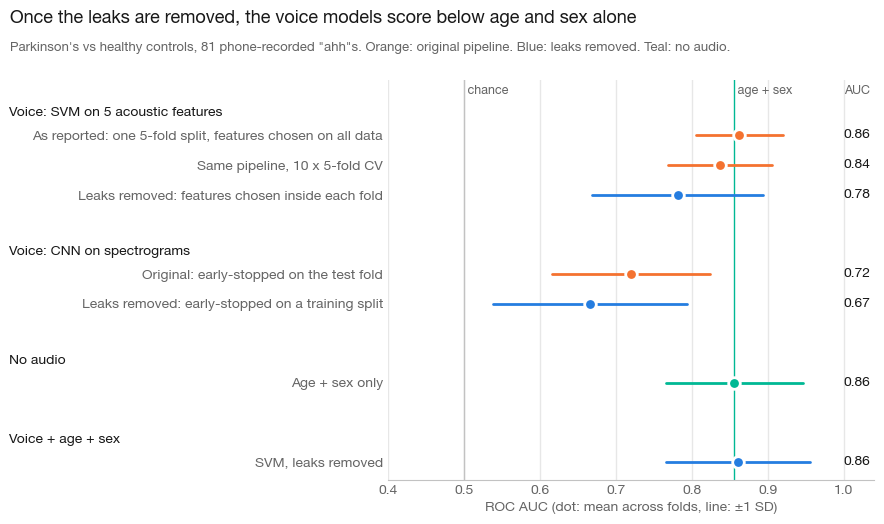

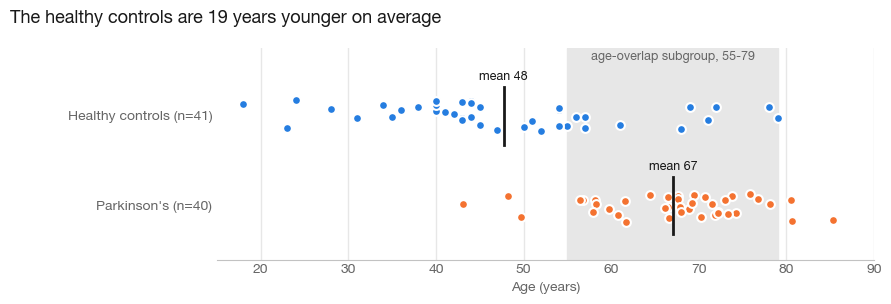

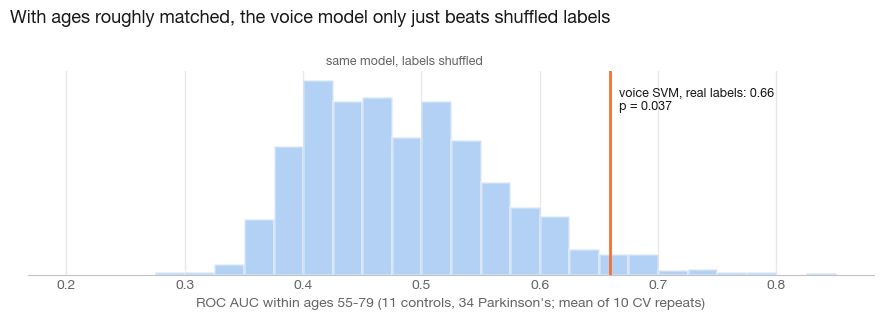

In [16]:
import matplotlib.pyplot as plt

THEMES = {
    'light': {'surface': '#ffffff', 'ink': '#191919', 'ink2': '#666666', 'grid': '#e7e7e7', 'axis': '#c2c2c2',
              'clean': '#257de0', 'leaky': '#f47230', 'demo': '#00b894'},
    'dark': {'surface': '#191919', 'ink': '#efefef', 'ink2': '#9c9c9c', 'grid': '#303030', 'axis': '#474747',
             'clean': '#338ced', 'leaky': '#e76624', 'demo': '#00a888'},
}
plt.rcParams.update({'font.family': ['Helvetica Neue', 'Helvetica', 'Arial', 'DejaVu Sans'], 'font.size': 10,
                     'svg.fonttype': 'none', 'pdf.fonttype': 42})
DOCS_FIG_DIR = ROOT / 'docs' / 'figures'
DOCS_FIG_DIR.mkdir(parents=True, exist_ok=True)


def style_axes(ax, th):
    ax.set_facecolor(th['surface'])
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(th['axis'])
    ax.tick_params(colors=th['ink2'], length=0)
    ax.xaxis.label.set_color(th['ink2'])
    ax.grid(axis='x', color=th['grid'], linewidth=1)
    ax.set_axisbelow(True)


def save(fig, name, theme):
    fig.savefig(ASSETS_DIR / f'{name}_{theme}.png', dpi=200, facecolor=fig.get_facecolor())
    if theme == 'light':
        fig.savefig(DOCS_FIG_DIR / f'{name}.pdf', facecolor=fig.get_facecolor())


def fig_auc_by_model(theme):
    th = THEMES[theme]
    items = [  # (group, label, summary, role)
        ('Voice: SVM on 5 acoustic features', 'As reported: one 5-fold split, features chosen on all data',
         orig_5fold['t=0.5'], 'leaky'),
        ('Voice: SVM on 5 acoustic features', 'Same pipeline, 10 x 5-fold CV', svm_leaky['t=0.5'], 'leaky'),
        ('Voice: SVM on 5 acoustic features', 'Leaks removed: features chosen inside each fold',
         svm_clean['t=0.5'], 'clean'),
        ('Voice: CNN on spectrograms', 'Original: early-stopped on the test fold', cnn_leaky['t=0.5'], 'leaky'),
        ('Voice: CNN on spectrograms', 'Leaks removed: early-stopped on a training split', cnn_clean['t=0.5'], 'clean'),
        ('No audio', 'Age + sex only', age_lr['t=0.5'], 'demo'),
        ('Voice + age + sex', 'SVM, leaks removed', voice_age_svm['t=0.5'], 'clean'),
    ]
    fig, ax = plt.subplots(figsize=(9, 5.4), facecolor=th['surface'])
    style_axes(ax, th)
    ypos, yticks, ylabels, group_rows, y_cursor, last_group = [], [], [], [], 0, None
    for group, label, s, role in items:
        if group != last_group:
            y_cursor += 0.9 if last_group else 0
            group_rows.append((group, y_cursor))
            y_cursor += 0.75
            last_group = group
        ypos.append(y_cursor)
        yticks.append(y_cursor)
        ylabels.append(label)
        y_cursor += 1
    age_ref = age_lr['t=0.5']['auc']['mean']
    ax.axvline(0.5, color=th['axis'], linewidth=1, zorder=1)
    ax.axvline(age_ref, color=th['demo'], linewidth=1, zorder=1)
    for (group, label, s, role), yp in zip(items, ypos):
        m, sd = s['auc']['mean'], s['auc']['sd']
        ax.plot([m - sd, min(m + sd, 1)], [yp, yp], color=th[role], linewidth=2, solid_capstyle='round', zorder=2)
        ax.scatter([m], [yp], s=70, color=th[role], edgecolor=th['surface'], linewidth=2, zorder=3)
        ax.text(1.035, yp, f'{m:.2f}', va='center', ha='right', color=th['ink'], fontsize=10)
    for group, gy in group_rows:
        ax.annotate(group, xy=(0.01, gy), xycoords=('figure fraction', 'data'), ha='left', va='center',
                    color=th['ink'], fontsize=10, fontweight='bold')
    ax.set_yticks(yticks, ylabels)
    ax.set_ylim(y_cursor - 0.4, -1.1)
    ax.set_xlim(0.4, 1.04)
    ax.set_xticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    ax.set_xlabel('ROC AUC (dot: mean across folds, line: ±1 SD)')
    ax.text(0.5, -0.75, ' chance', color=th['ink2'], fontsize=9, va='center')
    ax.text(age_ref, -0.75, ' age + sex', color=th['ink2'], fontsize=9, va='center')
    ax.text(1.035, -0.75, 'AUC', color=th['ink2'], fontsize=9, va='center', ha='right')
    fig.suptitle('Once the leaks are removed, the voice models score below age and sex alone',
                 x=0.01, ha='left', color=th['ink'], fontsize=13, fontweight='bold')
    fig.text(0.01, 0.905, 'Parkinson\'s vs healthy controls, 81 phone-recorded "ahh"s. Orange: original pipeline. '
             'Blue: leaks removed. Teal: no audio.', ha='left', color=th['ink2'], fontsize=9.5)
    fig.subplots_adjust(left=0.43, right=0.97, top=0.85, bottom=0.11)
    save(fig, '01_auc_by_model', theme)
    return fig


def fig_age_by_group(theme):
    th = THEMES[theme]
    fig, ax = plt.subplots(figsize=(9, 3.2), facecolor=th['surface'])
    style_axes(ax, th)
    ax.axvspan(AGE_LO, AGE_HI, color=th['grid'], zorder=0)
    rng = np.random.default_rng(SEED)
    for g, (name, yp) in enumerate([('Healthy controls', 1), ("Parkinson's", 0)]):
        a = age[y == g]
        ax.scatter(a, yp + rng.uniform(-0.18, 0.18, len(a)), s=40, color=th['clean'] if g == 0 else th['leaky'],
                   edgecolor=th['surface'], linewidth=1.5, zorder=3)
        ax.plot([a.mean()] * 2, [yp - 0.32, yp + 0.32], color=th['ink'], linewidth=2, zorder=4)
        ax.text(a.mean(), yp + 0.36, f'mean {a.mean():.0f}', ha='center', va='bottom', color=th['ink'], fontsize=9)
    ax.set_yticks([1, 0], [f'Healthy controls (n={(y == 0).sum()})', f"Parkinson's (n={(y == 1).sum()})"])
    ax.set_ylim(-0.6, 1.75)
    ax.set_xlim(15, 90)
    ax.set_xlabel('Age (years)')
    ax.text((AGE_LO + AGE_HI) / 2, 1.72, f'age-overlap subgroup, {AGE_LO}-{AGE_HI}', ha='center', va='top',
            color=th['ink2'], fontsize=9)
    fig.suptitle('The healthy controls are 19 years younger on average', x=0.01, ha='left',
                 color=th['ink'], fontsize=13, fontweight='bold')
    fig.subplots_adjust(left=0.24, right=0.97, top=0.86, bottom=0.2)
    save(fig, '02_age_by_group', theme)
    return fig


def fig_subgroup(theme):
    th = THEMES[theme]
    fig, ax = plt.subplots(figsize=(9, 3.4), facecolor=th['surface'])
    style_axes(ax, th)
    bins = np.arange(0.2, 0.86, 0.025)
    ax.hist(perm_aucs, bins=bins, color=th['clean'], alpha=0.35, edgecolor=th['surface'], linewidth=2)
    obs = subgroup['voice_svm']['mean']
    ax.axvline(obs, color=th['leaky'], linewidth=2)
    ax.text(obs + 0.008, ax.get_ylim()[1] * 0.92, f"voice SVM, real labels: {obs:.2f}\n"
            f"p = {subgroup['voice_svm']['permutation_p']:.3f}", color=th['ink'], fontsize=9, va='top')
    ax.text(perm_aucs.mean(), ax.get_ylim()[1] * 1.02, 'same model, labels shuffled', ha='center',
            color=th['ink2'], fontsize=9, va='bottom')
    ax.set_yticks([])
    ax.set_xlabel(f'ROC AUC within ages {AGE_LO}-{AGE_HI} '
                  f'({(y[sub] == 0).sum()} controls, {(y[sub] == 1).sum()} Parkinson\'s; mean of 10 CV repeats)')
    fig.suptitle('With ages roughly matched, the voice model only just beats shuffled labels', x=0.01, ha='left',
                 color=th['ink'], fontsize=13, fontweight='bold')
    fig.subplots_adjust(left=0.03, right=0.97, top=0.8, bottom=0.2)
    save(fig, '03_subgroup_permutation', theme)
    return fig


for theme in ('dark', 'light'):
    figs = [fig_auc_by_model(theme), fig_age_by_group(theme), fig_subgroup(theme)]
    if theme == 'dark':
        for f in figs:
            plt.close(f)
plt.show()